## 1. Set Up


In [1]:
import os
import sys

# Dynamically point GDAL and PROJ to your active conda environment's folders
env_prefix = sys.prefix
os.environ["GDAL_DATA"] = os.path.join(env_prefix, "Library", "share", "gdal")
os.environ["PROJ_LIB"] = os.path.join(env_prefix, "Library", "share", "proj")

# Optional: prevents OpenMP threading conflicts in conda
os.environ["KMP_DUPLICATE_LIB_OK"] = "True"

import geopandas as gpd
import pandas as pd
import seaborn as sns
import pyogrio
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from IPython.display import display
import os


In [2]:
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR/"data"/"raw"
FIG_DIR = PROJECT_DIR/"docs"/"figures"

FIG_DIR.mkdir(parents=True, exist_ok=True) #understand later

CEDEN_PATH = DATA_DIR/"CEDEN_export.tsv"
NWIS_PATH = DATA_DIR/"resultphyschem.csv"
CARI_PATH = DATA_DIR/"CARI_v3_3_0.gdb"
S2S_PATH = DATA_DIR/"S2S_stations_2026-09-18-1455.csv"


# Loading all Datasets

In [3]:
df_ceden = pd.read_csv(CEDEN_PATH, sep="\t")
df_nwis = pd.read_csv(NWIS_PATH)
df_s2s = pd.read_csv(S2S_PATH)

gdf_cari = gpd.read_file(
    CARI_PATH,
    layer = "CARI_Polygons"
)

# Printing shapes of datasets, and CRS for CARI database
print("CEDEN:", df_ceden.shape)
print("NWIS:", df_nwis.shape)
print("S2S:", df_s2s.shape)
print("CARI:", gdf_cari.shape)

print("CARI CRS:", gdf_cari.crs)

# Storing values for easy access:
    #CEDEN: (1629151, 94)
# NWIS: (1428878, 81)
# S2S: (6648, 9)
# CARI: (1287921, 30)
# CARI CRS: EPSG:6414

C:\Users\SHordyk\AppData\Local\Temp\1\ipykernel_31940\185542943.py:1: DtypeWarning: Columns (0: STATIONCODE, 1: SAMPLETYPECODE, 2: LABBATCH, 3: LABSAMPLEID, 4: RESULT, 5: QACODE, 6: BATCHVERIFICATION, 7: COMPLIANCECODE, 8: SAMPLECOMMENTS, 9: COLLECTIONCOMMENTS, 10: RESULTSCOMMENTS, 11: BATCHCOMMENTS, 12: PREPPRESERVATIONNAME, 13: PREPPRESERVATIONDATE, 14: DIGESTEXTRACTMETHOD, 15: DIGESTEXTRACTDATE, 16: ANALYSISDATE, 17: EXPECTEDVALUE, 18: LABAGENCY, 19: SUBMITTINGAGENCY, 20: SUBMISSIONCODE, 21: OCCUPATIONMETHOD, 22: STARTINGBANK, 23: UNITDISTANCEFROMBANK, 24: UNITSTREAMWIDTH, 25: UNITSTATIONWATERDEPTH, 26: HYDROMOD, 27: HYDROMODLOC, 28: LOCATIONDETAILWQCOMMENTS, 29: SAMPLEID, 30: STATIONLUCODE, 31: RB_NUMBER, 32: WATERBODY_TYPE, 33: HUC12_NAME, 34: HUC12_NUMBER) have mixed types. Specify dtype option on import or set low_memory=False.
  df_ceden = pd.read_csv(CEDEN_PATH, sep="\t")
C:\Users\SHordyk\AppData\Local\Temp\1\ipykernel_31940\185542943.py:2: DtypeWarning: Columns (0: ActivityMe

CEDEN: (1629151, 94)
NWIS: (1428878, 81)
S2S: (6648, 9)
CARI: (1287921, 30)
CARI CRS: EPSG:6414


In [4]:
# Dataset summaries
datasets = {
    "CEDEN":df_ceden, #naming
    "NWIS":df_nwis,
    "CARI": gdf_cari,
    "Safe-to-Swim":df_s2s
}
# Printing out names and labels 
for name, data in datasets.items():
    print(f"{name}: {data.shape[0]:,} rows, {data.shape[1]:,} columns")

print("\nCARI CR:", gdf_cari.crs)

CEDEN: 1,629,151 rows, 94 columns
NWIS: 1,428,878 rows, 81 columns
CARI: 1,287,921 rows, 30 columns
Safe-to-Swim: 6,648 rows, 9 columns

CARI CR: EPSG:6414


In [5]:
# Looking at column names 
for name, data in datasets.items(): ### for each item in datasets dictionary, assign its key to "name" and value to "data", from .items()
    print(f"\n{name} columns:")
    print(data.columns.tolist())

# Need STATIONCODE, STATIONNAME, LATITUDE, LONGITUDE, SAMPLEDATE, ANALYTE, RESULT, UNIT, RESULTQUALCODE, MDL, RL, WATERBODY_TYPE 


CEDEN columns:
['PROGRAM', 'PARENTPROJECT', 'PROJECT', 'STATIONNAME', 'STATIONCODE', 'SAMPLEDATE', 'COLLECTIONTIME', 'LOCATIONCODE', 'COLLECTIONDEPTH', 'UNITCOLLECTIONDEPTH', 'SAMPLETYPECODE', 'COLLECTIONREPLICATE', 'RESULTSREPLICATE', 'LABBATCH', 'LABSAMPLEID', 'MATRIXNAME', 'METHODNAME', 'ANALYTE', 'UNIT', 'RESULT', 'OBSERVATION', 'MDL', 'RL', 'RESULTQUALCODE', 'QACODE', 'BATCHVERIFICATION', 'COMPLIANCECODE', 'SAMPLECOMMENTS', 'COLLECTIONCOMMENTS', 'RESULTSCOMMENTS', 'BATCHCOMMENTS', 'EVENTCODE', 'PROTOCOLCODE', 'SAMPLEAGENCY', 'GROUPSAMPLES', 'COLLECTIONMETHODNAME', 'TARGETLATITUDE', 'TARGETLONGITUDE', 'COLLECTIONDEVICEDESCRIPTION', 'CALIBRATIONDATE', 'POSITIONWATERCOLUMN', 'PREPPRESERVATIONNAME', 'PREPPRESERVATIONDATE', 'DIGESTEXTRACTMETHOD', 'DIGESTEXTRACTDATE', 'ANALYSISDATE', 'DILUTIONFACTOR', 'EXPECTEDVALUE', 'LABAGENCY', 'SUBMITTINGAGENCY', 'SUBMISSIONCODE', 'OCCUPATIONMETHOD', 'STARTINGBANK', 'DISTANCEFROMBANK', 'UNITDISTANCEFROMBANK', 'STREAMWIDTH', 'UNITSTREAMWIDTH', 'STAT

In [6]:
# Checking CARI Fields   ### label what these are 
# Sam reminder - () tuple, [] list, {} set
cari_fields = [
    "CARI_id",
    "major_class",
    "clicklabel",
    "leglabellevel1",
    "salinity_modifier",
    "geometry",
]

missing = [
    col for col in cari_fields
    if col not in gdf_cari.columns
]

if missing:
    raise ValueError(f"Missing expected CARI columns: {missing}") # helps to rule out spellng errors in field names as well

## 2. CARI - Salinity Modifier Distribution

In [7]:
# Looking at salinity modifier distribution, after initial cleaning

cari_count = len(gdf_cari)

placeholders = ["Undefined", "N/A", "n/a"]

cari_sal = gdf_cari.loc[      #using .loc , a geopandas indexing method that lets you select rows based on a condition (here, only where salinity modifier is present and data is not missing)
    gdf_cari["salinity_modifier"].notna()
    & ~gdf_cari["salinity_modifier"].isin(placeholders)
].copy()   # created a copy of database to change/edit as needed

cari_sal_count = len(cari_sal)

percentage = cari_sal_count / cari_count * 100

print(f"Total CARI Polygons: {cari_count:,}")
print(f"CARI polygons with salinity modifiers: {cari_sal_count:,}")
print(f"Percentage with salinity modifiers: {percentage:.1f}%")

Total CARI Polygons: 1,287,921
CARI polygons with salinity modifiers: 371,872
Percentage with salinity modifiers: 28.9%


In [8]:
# Salinity Modifier Categories

modifier_counts = (
    cari_sal["salinity_modifier"]
    .value_counts(dropna=False)
    .rename_axis("Salinity modifier")      #Usually, the types of salinity modifiers would be stored in index not a seperate column. This renames axis (header)
    .reset_index(name="Polygon count")     # And this converts the index into a regular column with a name (header). Also creates a new dataframe from series, seperates index and values into two columns
)

display(modifier_counts)

,Salinity modifier,Polygon count
0,Saline,247112
1,Mesohaline,54401
2,Oligohaline,40988
3,Fresh,27037
4,Bar-built (Variable),2334


In [9]:
# Major Classifications in CARI - Open Water and Wetlands (no inland I guess)

major_class__counts = (
    cari_sal["major_class"]
    .value_counts(dropna=False)
    .rename_axis("Major class")
    .reset_index(name="Polygon count")
)

display(major_class__counts)


,Major class,Polygon count
0,Wetland,214364
1,Open Water,157508


In [10]:
# More detailed classifications
# Clicklabel, and associated clickcode, are the most detailed wetland type code in CARI. 
# leglabel is a more generalized classification that groups aquatic features together
# There are inland nonsaline bodies - lacustrine wetlands (lakes, no human structures like dams)

for col in ["clicklabel", "leglabellevel1"]:
    print(f"\n{col}")
    display(
        cari_sal[col]
        .value_counts(dropna=False)
        .rename("Polygon count")
        .to_frame()
    )


clicklabel


,Polygon count
clicklabel,
Estuarine Saline Natural Intertidal Emergent,96722
Estuarine Natural Subtidal Eelgrass,67511
Marine Natural Subtidal Eelgrass,53292
Estuarine Saline Natural Intertidal Non-vegetated,45501
Estuarine Saline Unnatural Intertidal Vegetated,29496
...,...
Depressional Natural,1
Lacustrine Managed,1
Riverine Unnatural,1



leglabellevel1


,Polygon count
leglabellevel1,
Tidal Marsh,137543
Eelgrass,120803
Tidal Flat and Marsh Panne,47269
Subtidal Water,26019
Rocky Shore,9502
Pond and associated vegetation,9162
Managed and Muted Tidal Habitats,5500
Beach,4951
Vernal Pool,4210


In [11]:
# Plotting basics and settings
matplotlib.use("inline")

COLORS = {
"blue": "#356A8A",
"teal": "#5B9A91",
"gold": "#D6A84B",
"coral": "#C97861",
"purple": "#8176A8",
"gray": "#8A9299",
"light_gray": "#D9DEE2",
"dark": "#263238",
}

plt.rcParams.update({
"figure.facecolor": "white",
"axes.facecolor": "white",
"savefig.facecolor": "white",
"figure.figsize": (8, 5),
"figure.dpi": 120,
"savefig.dpi": 300,
"font.family": "DejaVu Sans",
"font.size": 10,
"axes.titlesize": 13,
"axes.titleweight": "semibold",
"axes.labelsize": 10,
"axes.labelcolor": COLORS["dark"],
"xtick.color": COLORS["dark"],
"ytick.color": COLORS["dark"],
"text.color": COLORS["dark"],
"axes.spines.top": False,
"axes.spines.right": False,
"axes.edgecolor": COLORS["light_gray"],
"axes.linewidth": 0.8,
"axes.grid": True,
"grid.color": COLORS["light_gray"],
"grid.linewidth": 0.7,
"grid.alpha": 0.7,
"axes.axisbelow": True,
"legend.frameon": False,
"savefig.bbox": "tight",
})

def finish_figure(fig, filename):
#Apply consistent spacing, save a figure, and display it.
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, facecolor="white")
    plt.show()
    plt.close(fig)

def style_map_axis(ax, title):
#Apply shared styling to geographic maps.
    ax.set_title(title, loc="left", pad=10)
    ax.set_axis_off()

In [12]:
### 3. CARI Figures 

### Fig 1. CARI MAJOR CLASSIFICATIONS
plot_data = (
    cari_sal["major_class"]
    .value_counts()
    .sort_values()
)

print(type(plot_data))
print(plot_data)
print("Number pf categproes:", len(plot_data))

<class 'pandas.Series'>
major_class
Open Water    157508
Wetland       214364
Name: count, dtype: int64
Number pf categproes: 2


findfont: Failed to find font weight semibold, now using 700.


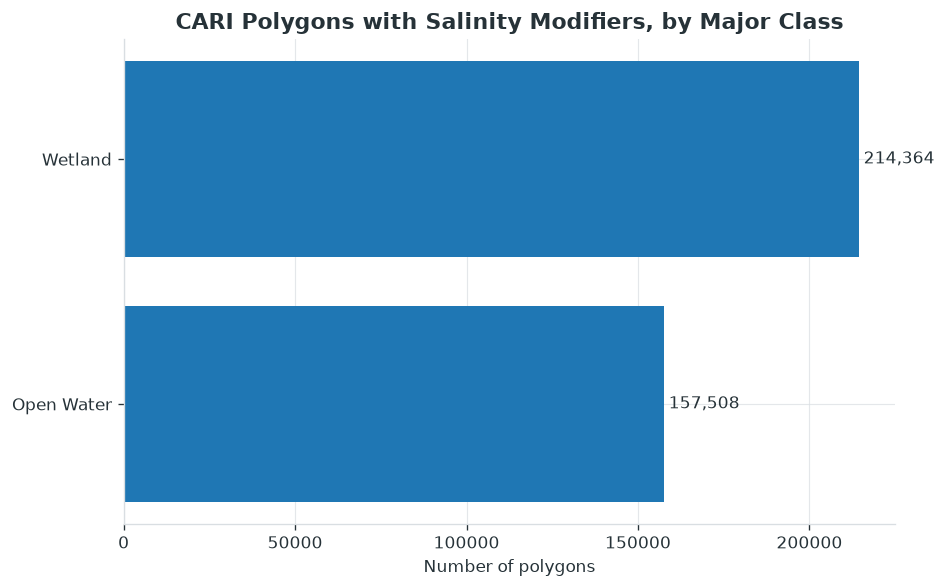

In [13]:

fig, ax = plt.subplots(figsize=(8,5))

ax.barh(
    plot_data.index.astype(str),
    plot_data.values
)

ax.set_title( "CARI Polygons with Salinity Modifiers, by Major Class")
ax.set_xlabel("Number of polygons")
ax.set_ylabel("")

# Count labels
for i, value in enumerate(plot_data.values):
    ax.text(value, i, f" {value:,}", va="center")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "O1_cari_majorclass.png",
    bbox_inches = "tight"
)
plt.show()



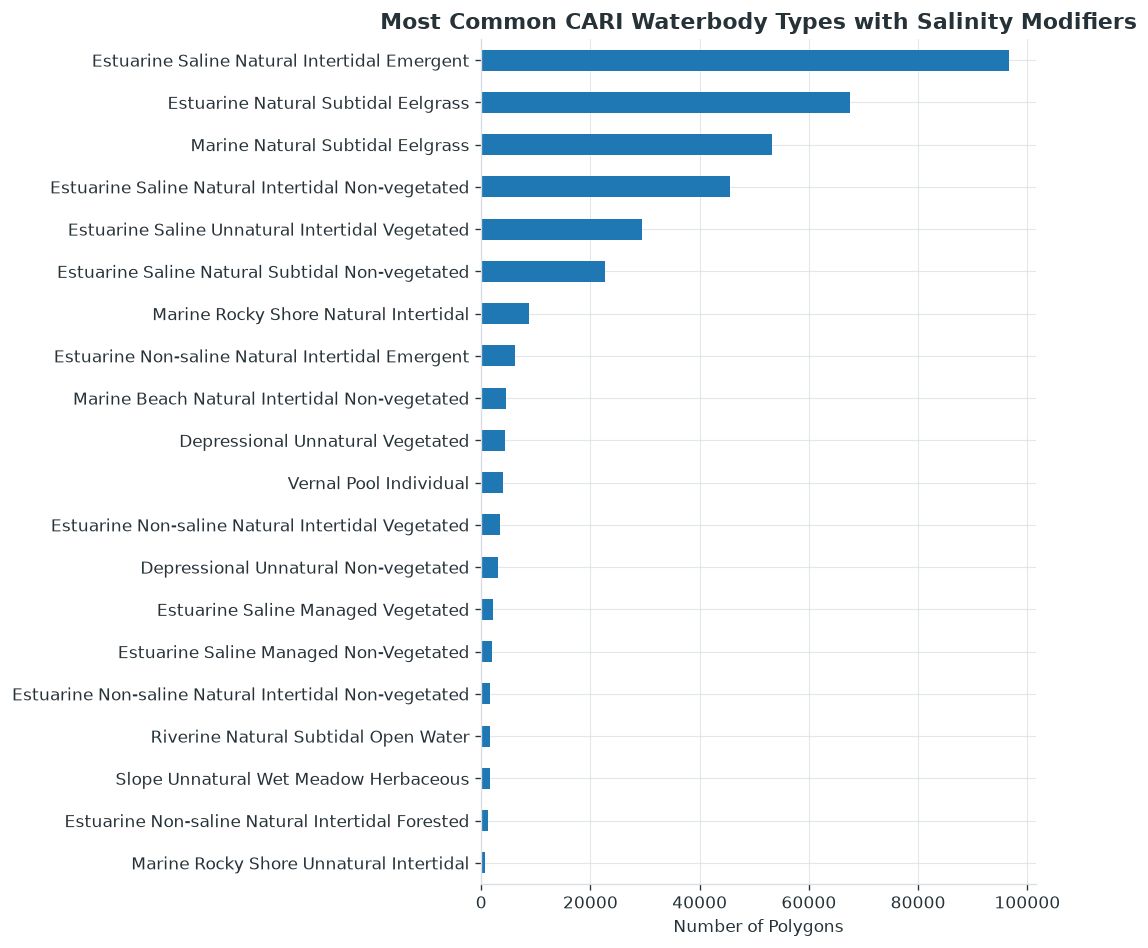

In [14]:
### Fig 1B: Detailed CARI Waterbody Types, map
type_col = "clicklabel"

type_counts = (
    cari_sal[type_col]
    .value_counts()
    .sort_values(ascending=False)
)

# Just keeping most common categories for readability 
top_n = 20 
top_types = type_counts.head(top_n).sort_values()

fig,ax = plt.subplots(figsize=(9,8))

top_types.plot(
    kind="barh",
    ax=ax
)

ax.set_title(f"Most Common CARI Waterbody Types with Salinity Modifiers")
ax.set_xlabel("Number of Polygons")
ax.set_ylabel("")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "O2_cari_waterbody_type.png",
    bbox_inches = "tight"
)

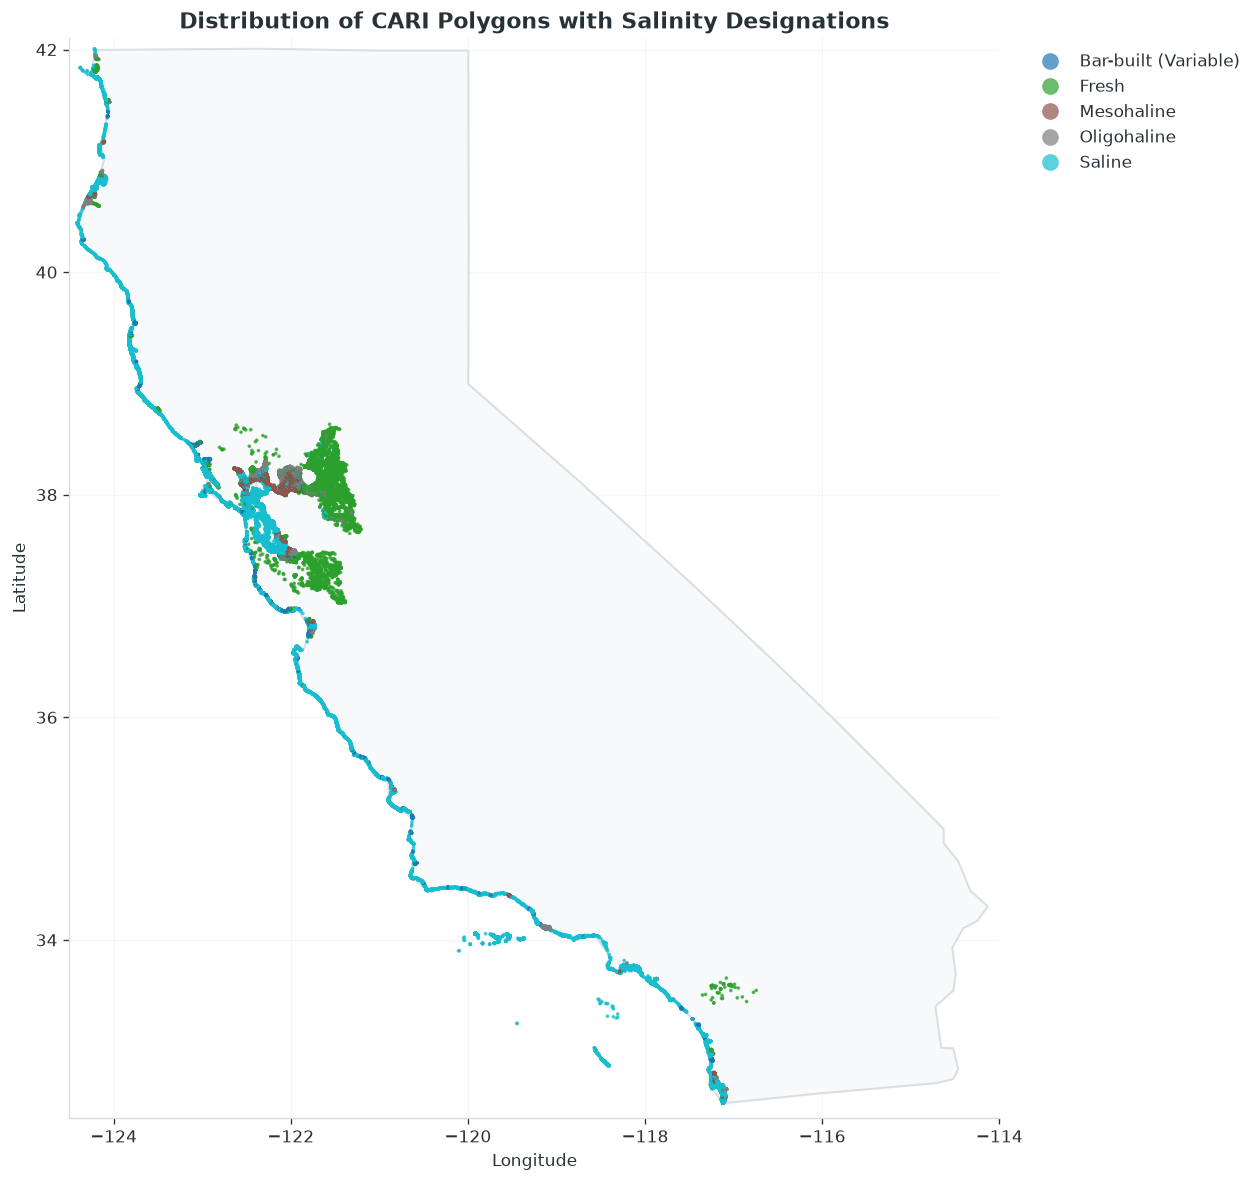

In [17]:
# Plotting map of CARI distribution with salinity modifiers, based on salinity type 

# Convert CARI polygons to representative points and reproject to WGS84
cari_sal_points = cari_sal.copy()
cari_sal_points["geometry"] = cari_sal_points.geometry.representative_point()
cari_sal_points = cari_sal_points.to_crs("EPSG:4326")

# Initialize figure (overriding default figsize for a taller map layout)
fig, ax = plt.subplots(figsize=(10, 12))

url = "https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json"
us_states = gpd.read_file(url)
ca_state = us_states[us_states["name"] == "California"].to_crs("EPSG:4326")
ca_state.plot(
    ax=ax,
    color="#F7F9FA",  # Very light off-white fill
    edgecolor=COLORS["light_gray"],  # Clean subtle border using your palette
    linewidth=1.2,
)
# Plot your salinity designation points
cari_sal_points.plot(
    ax=ax,
    column="salinity_modifier",
    categorical=True,
    legend=True,
    markersize=1.5,
    alpha=0.7,
    legend_kwds={
        "bbox_to_anchor": (1.02, 1),
        "loc": "upper left",
        "frameon": False,
    },
)

ax.set_title("Distribution of CARI Polygons with Salinity Designations")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_xlim(-124.5, -114.0)
ax.set_ylim(32.4, 42.1)
ax.grid(True, alpha=0.3)

plt.savefig(
    FIG_DIR / "03_cari_salinity_distribution.png",
     bbox_inches="tight", dpi=300
)
plt.show()

In [ ]:
# Checking lakes and other non saline sources, 

In [22]:
### 4. CEDEN Analyte 
print("Number of CEDEN records:", len(df_ceden))

display(
    df_ceden["ANALYTE"]
    .value_counts()
    .to_frame("Record count")
)# Only pulled salinity-related fields

Number of CEDEN records: 1629151


,Record count
ANALYTE,
"SpecificConductivity, Total",844418
"Salinity, Total",692156
"SpecificConductivity, Not Recorded",58482
"Chloride, Total",19091
"Chloride, Dissolved",12181
"Chloride, Not Recorded",2146
"Salinity, Dissolved",669
SpecificConductivity,3
Salinity,3


In [ ]:
# Picking select analytes - next time make a copy. Since I ran this once, CEDEN is already cleaned. 

""" analytes = df_ceden['ANALYTE'].unique()
#searching for keywords related to salinity, conductivity, and conductance
salinity_related = [a for a in analytes if any(kw in a.lower() for kw in ['conductance', 'conductivity', 'salinity', 'chloride'])]
print(salinity_related)
salinity_analytes = ['Salinity, Total', 'Salinity', 'Salinity, Dissolved',
                      'SpecificConductivity, Total', 'SpecificConductivity',
                      'SpecificConductivity, Not Recorded', 'SpecificConductivity, Dissolved',
                      'Chloride, Total', 'Chloride, Dissolved', 'Chloride, Not Recorded']
# Creates a temporary true false mask for the analytes of interest, then groups by analyte and unit to get counts. Move to last line in cell to display
df_ceden[df_ceden['ANALYTE'].isin(salinity_analytes)].groupby(['ANALYTE', 'UNIT']).size()
df_ceden_salinity = df_ceden[df_ceden['ANALYTE'].isin(salinity_analytes)].copy()
df_ceden_salinity.shape """

In [ ]:
#Drop entries missing lat and long. EDUT want count of how many missing lat long
df_ceden_salinity = df_ceden.dropna(subset=['LATITUDE', 'LONGITUDE'])
# Extract unique STATIONCODE and STATIONNAME combinations to avoid duplicates in the GeoDataFrame - fix next time, too critical
df_ceden_sal_u = df_ceden_salinity.drop_duplicates(subset=['STATIONCODE', 'STATIONNAME'])
# Drop entries with missing or NaN values in the 'RESULT' column
df_ceden_sal_u = df_ceden_sal_u.dropna(subset=['RESULT'])
df_ceden_sal_u.shape

(12116, 94)

In [ ]:
## 5. NWIS Cleaning 
### 4. CEDEN Analyte 
print("Number of NIWS records", len(df_nwis))

display(
    df_nwis['CharacteristicName']
    .value_counts()
    .to_frame("Record count")
)# Only pulled salinity-related fields

Number of NIWS records 1428878


,Record count
CharacteristicName,
Specific conductance,944295
Salinity,356827
Chloride,127756


In [ ]:
# If preparing for actual dataset, check units and do necessary conversions

In [32]:
""" # Again - already cleaned without making a copy. Recorded here for repeatability
# Checking what values exist for NWIS CharacteristicName, name of analyte. 
df_nwis['CharacteristicName'].value_counts()
# Looking at result values, whcih collumn do we want. ResultMeasureValue, ResultStatusIdentifier
df_nwis['ResultStatusIdentifier'].value_counts();
# Print values of ResultMeasureValue to see what they look like
df_nwis['ResultMeasure/MeasureUnitCode'].value_counts();
# Filtering NWIS as well. Dropping any without lat long, 
df_nwis = df_nwis.dropna(subset=['ActivityLocation/LatitudeMeasure', 'ActivityLocation/LongitudeMeasure'])
df_nwis.shape
# Dropping without any result values, ResultMeasureValue or unit. ResultMeasureValue is the actual measurement, ResultMeasure/MeasureUnitCode is the unit of measurement.
df_nwis = df_nwis.dropna(subset=['ResultMeasureValue', 'ResultMeasure/MeasureUnitCode'])
df_nwis.shape
# Keeping only columns needed. MonitoringLocationIdentifier, MonitoringLocationName, ActivityLocation/LatitudeMeasure, ActivityLocation/LongitudeMeasure, ActivityStartDate, CharacteristicName, ResultMeasureValue, ResultMeasure/MeasureUnitCode, ResultSampleFractionText, ResultDetectionConditionText, ResultStatusIdentifier, MeasureQualifierCode, OrganizationIdentifier, OrganizationFormalName, USGSPCode
df_nwis_sal = df_nwis[['MonitoringLocationIdentifier', 'MonitoringLocationName', 'ActivityLocation/LatitudeMeasure', 'ActivityLocation/LongitudeMeasure', 'ActivityStartDate', 'CharacteristicName', 'ResultMeasureValue', 'ResultMeasure/MeasureUnitCode', 'ResultSampleFractionText', 'ResultDetectionConditionText', 'ResultStatusIdentifier', 'MeasureQualifierCode', 'OrganizationIdentifier', 'OrganizationFormalName', 'USGSPCode']]
#Keep only columns needed: STATIONCODE, STATIONNAME, LATITUDE, LONGITUDE, ANALYTE, UNIT, RESULT, RESULTQUALCODE, MDL, RL
df_ceden_sal_u = df_ceden_sal_u[['STATIONCODE', 'STATIONNAME', 'LATITUDE', 'LONGITUDE', 'ANALYTE', 'UNIT', 'RESULT', 'RESULTQUALCODE', 'MDL', 'RL']]
df_ceden_sal_u.head() """
df_ceden_sal_u.shape

(12116, 94)

In [34]:
# Safe to Swim data 
print("Safe-to-Swim records:", len(df_s2s))
print("\nCollumns:")
print(df_s2s.columns.tolist)

print("\nMissing Coordinates:")
print(
    df_s2s[
         ["TARGETLONGITUDE", "TARGETLATITUDE"]
    ].isna().any(axis=1).sum()
)

print("\nUnique station codes:")
print(df_s2s["STATIONCODE"].nunique()

SyntaxError: incomplete input (187129652.py, line 14)

In [ ]:
# Building point dataset and GeoDataFrame from S2S

In [ ]:
# Converting NWIS and CEDEN into GeoDataFrames 


# Reproject point datasets

In [ ]:
# Compute spatial joins, preserving all point-polygon matches rather than assume one-to-one

# Join function

# Joins 

In [ ]:
# Check how many s2s monitoring locations have matches 

In [ ]:
# Compute coverage within CARI salinity subset

In [9]:
df_ceden = pd.read_csv(CEDEN_PATH, sep="\t")
df_ceden.head(5);
df_ceden.shape;
df_ceden.columns.tolist();


C:\Users\SHordyk\AppData\Local\Temp\1\ipykernel_31432\824078069.py:1: DtypeWarning: Columns (0: STATIONCODE, 1: SAMPLETYPECODE, 2: LABBATCH, 3: LABSAMPLEID, 4: RESULT, 5: QACODE, 6: BATCHVERIFICATION, 7: COMPLIANCECODE, 8: SAMPLECOMMENTS, 9: COLLECTIONCOMMENTS, 10: RESULTSCOMMENTS, 11: BATCHCOMMENTS, 12: PREPPRESERVATIONNAME, 13: PREPPRESERVATIONDATE, 14: DIGESTEXTRACTMETHOD, 15: DIGESTEXTRACTDATE, 16: ANALYSISDATE, 17: EXPECTEDVALUE, 18: LABAGENCY, 19: SUBMITTINGAGENCY, 20: SUBMISSIONCODE, 21: OCCUPATIONMETHOD, 22: STARTINGBANK, 23: UNITDISTANCEFROMBANK, 24: UNITSTREAMWIDTH, 25: UNITSTATIONWATERDEPTH, 26: HYDROMOD, 27: HYDROMODLOC, 28: LOCATIONDETAILWQCOMMENTS, 29: SAMPLEID, 30: STATIONLUCODE, 31: RB_NUMBER, 32: WATERBODY_TYPE, 33: HUC12_NAME, 34: HUC12_NUMBER) have mixed types. Specify dtype option on import or set low_memory=False.
  df_ceden = pd.read_csv(CEDEN_PATH, sep="\t")


In [ ]:
# Preview columns 
df_ceden.columns.tolist();
df_nwis.columns.tolist()

In [4]:
df_nwis= pd.read_csv(r"C:\Users\SHordyk\Desktop\safetoswim-waterbodies\data\raw\resultphyschem.csv")
df_nwis.head(5);
df_nwis.shape;
df_nwis.columns.tolist()

C:\Users\SHordyk\AppData\Local\Temp\1\ipykernel_25936\55912846.py:1: DtypeWarning: Columns (0: ActivityMediaSubdivisionName, 1: ActivityEndDate, 2: ActivityEndTime/Time, 3: ActivityEndTime/TimeZoneCode, 4: ActivityRelativeDepthName, 5: ActivityDepthHeightMeasure/MeasureValue, 6: ActivityDepthHeightMeasure/MeasureUnitCode, 7: ActivityDepthAltitudeReferencePointText, 8: ActivityTopDepthHeightMeasure/MeasureUnitCode, 9: ActivityBottomDepthHeightMeasure/MeasureUnitCode, 10: ProjectIdentifier, 11: ProjectName, 12: ActivityConductingOrganizationText, 13: MonitoringLocationName, 14: ActivityCommentText, 15: SampleAquifer, 16: HydrologicCondition, 17: HydrologicEvent, 18: SampleCollectionMethod/MethodDescriptionText, 19: ResultDetectionConditionText, 20: MethodSpeciationName, 21: ResultSampleFractionText, 22: ResultMeasureValue, 23: MeasureQualifierCode, 24: StatisticalBaseCode, 25: ResultWeightBasisText, 26: ResultTimeBasisText, 27: ResultTemperatureBasisText, 28: DataQuality/PrecisionValue, 

['OrganizationIdentifier',
 'OrganizationFormalName',
 'ActivityIdentifier',
 'ActivityTypeCode',
 'ActivityMediaName',
 'ActivityMediaSubdivisionName',
 'ActivityStartDate',
 'ActivityStartTime/Time',
 'ActivityStartTime/TimeZoneCode',
 'ActivityEndDate',
 'ActivityEndTime/Time',
 'ActivityEndTime/TimeZoneCode',
 'ActivityRelativeDepthName',
 'ActivityDepthHeightMeasure/MeasureValue',
 'ActivityDepthHeightMeasure/MeasureUnitCode',
 'ActivityDepthAltitudeReferencePointText',
 'ActivityTopDepthHeightMeasure/MeasureValue',
 'ActivityTopDepthHeightMeasure/MeasureUnitCode',
 'ActivityBottomDepthHeightMeasure/MeasureValue',
 'ActivityBottomDepthHeightMeasure/MeasureUnitCode',
 'ProjectIdentifier',
 'ProjectName',
 'ActivityConductingOrganizationText',
 'MonitoringLocationIdentifier',
 'MonitoringLocationName',
 'ActivityCommentText',
 'SampleAquifer',
 'HydrologicCondition',
 'HydrologicEvent',
 'ActivityLocation/LatitudeMeasure',
 'ActivityLocation/LongitudeMeasure',
 'SampleCollectionMeth

In [6]:
gdp_cari_path = r"C:\Users\SHordyk\Desktop\safetoswim-waterbodies\data\raw\CARI_v3_3_0.gdb"
layers = pyogrio.list_layers(gdp_cari_path)
#print(layers)

c:\Users\SHordyk\AppData\Local\ESRI\conda\envs\safe_gis_env\Lib\site-packages\pyogrio\core.py:169: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_list_layers(get_vsi_path_or_buffer(path_or_buffer))


In [7]:
# Checking that the CARI polygons are as expected, waterbodies not buffers
gdf_cari = gpd.read_file(gdp_cari_path, layer="CARI_Polygons")
print(gdf_cari.columns.tolist())
#gdf_cari.head()

c:\Users\SHordyk\AppData\Local\ESRI\conda\envs\safe_gis_env\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(
c:\Users\SHordyk\AppData\Local\ESRI\conda\envs\safe_gis_env\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts. The processing may be really slow.  You can skip the processing by setting METHOD=SKIP, or only make it analyze counter-clock wise parts by setting METHOD=ONLY_CCW if you can assume that the outline of holes is counter-clock wise defined. Further messages of this type will be suppressed.
  return ogr_read(


['clickcode', 'clicklabel', 'name', 'orig_dataset', 'orig_class', 'organization', 'orig_dataset_pubyear', 'process_adjustment', 'source_data', 'source_estimatedyear', 'orig_scale', 'legend_headings', 'legcode', 'leglabellevel1', 'leglabellevel2', 'major_class', 'wetland_class', 'anthropogenic_modifier', 'wetland_type', 'wetland_subtype', 'tidal_modifier', 'vegetation_modifier', 'salinity_modifier', 'salinity_source', 'salinity_additional_information', 'lastupdate', 'CARI_id', 'Shape_Length', 'Shape_Area', 'geometry']


Investigating CARI Salinity Modifers Distribution 

In [8]:
# Cari count
cari_count = len(gdf_cari)
# CARI without salinity modifiers
placeholders = ["Undefined", "N/A"]
cari_sal = gdf_cari[
    gdf_cari['salinity_modifier'].notna() &
    ~gdf_cari['salinity_modifier'].isin(placeholders)
]
cari_sal_count = len(cari_sal)
print(f"Total CARI polygons: {cari_count}")
print(f"Total CARI polygons with salinity modifiers: {cari_sal_count}")
percentage = (cari_sal_count / cari_count) * 100
print(f"Percentage of CARI with salinity modifer: {percentage:.1f}% ")
print(gdf_cari['salinity_modifier'].unique())

Total CARI polygons: 1287921
Total CARI polygons with salinity modifiers: 371872
Percentage of CARI with salinity modifer: 28.9% 
<StringArray>
['Bar-built (Variable)',                  'N/A',            'Undefined',
               'Saline',           'Mesohaline',          'Oligohaline',
                'Fresh']
Length: 7, dtype: str


C:\Users\SHordyk\AppData\Local\Temp\1\ipykernel_25936\3233915949.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


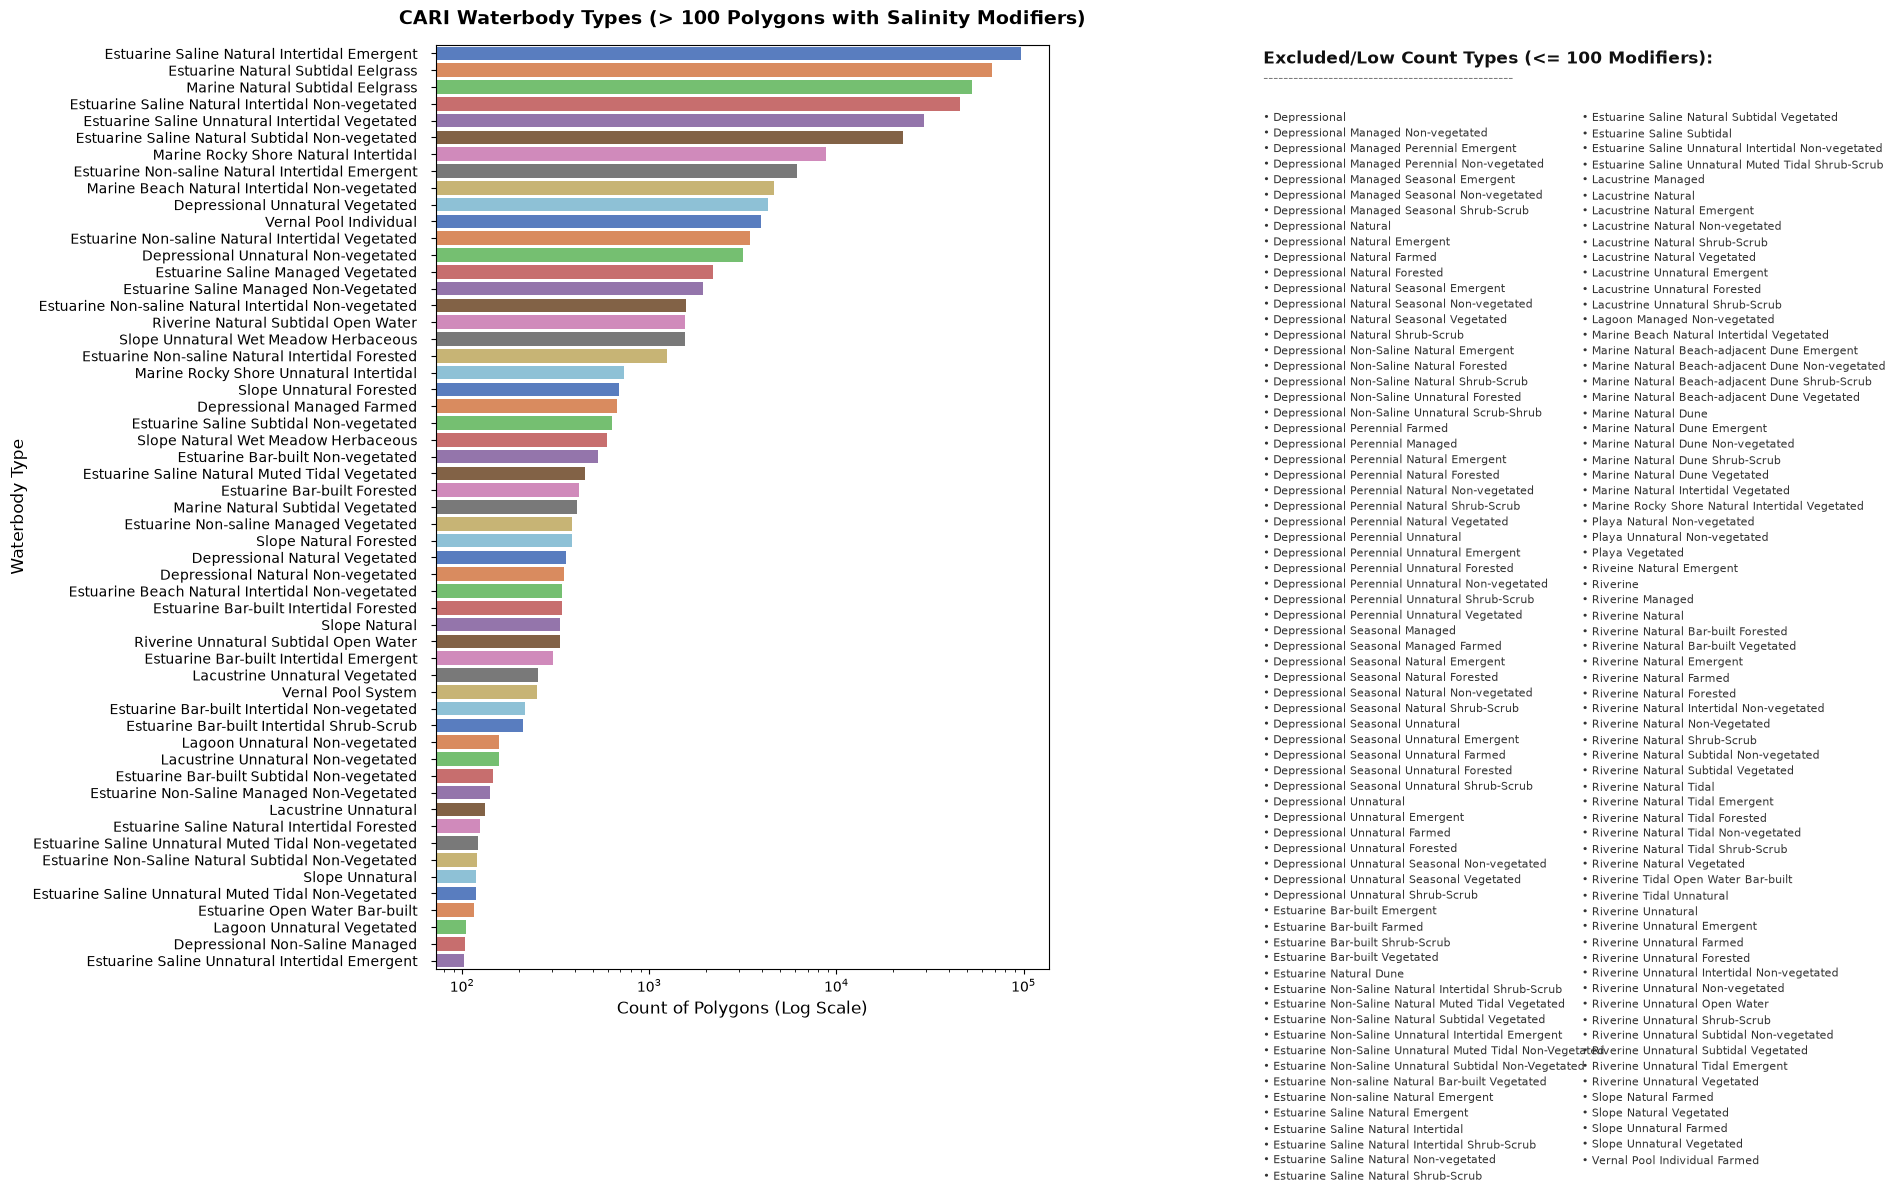

In [10]:
# Distribution of CARI waterbody types with salinity modifiers. Don't list ones with no values, print list seperately on image 

type_col = 'clicklabel' 

# --- Step 2: Separate and Filter Data (> 100 Counts) ---
plot_data = cari_sal[cari_sal[type_col].notna()]
active_counts = plot_data[type_col].value_counts()

# Only keep waterbody types with MORE THAN 100 entries
types_above_100 = active_counts[active_counts > 100].index
filtered_plot_data = plot_data[plot_data[type_col].isin(types_above_100)].copy()

# CRITICAL FIX: Tell pandas to drop the empty category tags completely
if hasattr(filtered_plot_data[type_col], 'cat'):
    filtered_plot_data[type_col] = filtered_plot_data[type_col].cat.remove_unused_categories()

# Everything else goes to the excluded list on the right
all_unique_types = set(gdf_cari[type_col].dropna().unique())
types_without_values = sorted(list(all_unique_types - set(types_above_100)))

# --- Step 3: Setup side-by-side layout ---
# Increased width to 18 and height to 12 to provide structural breathing room
fig, (ax_plot, ax_text) = plt.subplots(
    1, 2, figsize=(18, 12), gridspec_kw={'width_ratios': [2.5, 2.5]}  # Balanced 50/50 split
)

# --- Step 4: Plot the distribution (Seaborn) ---
sns.countplot(
    data=filtered_plot_data,
    y=type_col,
    order=types_above_100,  # Forces plot to sort highest to lowest
    ax=ax_plot,
    palette="muted"
)

# Change x-axis to log scale
ax_plot.set_xscale('log')

ax_plot.set_title("CARI Waterbody Types (> 100 Polygons with Salinity Modifiers)", fontsize=14, pad=15, weight='bold')
ax_plot.set_xlabel("Count of Polygons (Log Scale)", fontsize=12)
ax_plot.set_ylabel("Waterbody Type", fontsize=12)

# 🚀 Spacing optimization: adjust text padding on the y-axis
ax_plot.tick_params(axis='y', labelsize=10, pad=10) 

# --- Step 5: Split Excluded List into Two Balanced Columns ---
ax_text.axis('off') 

# Header text
ax_text.text(0.0, 0.98, "Excluded/Low Count Types (<= 100 Modifiers):", fontsize=12, weight='bold', color='#111111')
ax_text.text(0.0, 0.96, "-"*50, fontsize=10, color='#777777')

# Calculate the split point
half_size = int(np.ceil(len(types_without_values) / 2))
col1_items = types_without_values[:half_size]
col2_items = types_without_values[half_size:]

# Convert list slices to single text blocks
col1_text = "\n".join(f"• {item}" for item in col1_items)
col2_text = "\n".join(f"• {item}" for item in col2_items)

# Render Column 1 (Left side of the right panel)
ax_text.text(
    0.0, 0.93, col1_text, 
    transform=ax_text.transAxes, 
    fontsize=8, 
    verticalalignment='top',
    linespacing=1.4,
    color='#333333'
)

# Render Column 2 (Right side of the right panel)
ax_text.text(
    0.52, 0.93, col2_text, 
    transform=ax_text.transAxes, 
    fontsize=8, 
    verticalalignment='top',
    linespacing=1.4,
    color='#333333'
)

# Adjust layout bounding box properties to maximize canvas padding
plt.subplots_adjust(left=0.15, right=0.95, wspace=0.35)
plt.show()


C:\Users\SHordyk\AppData\Local\Temp\1\ipykernel_844\115067579.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


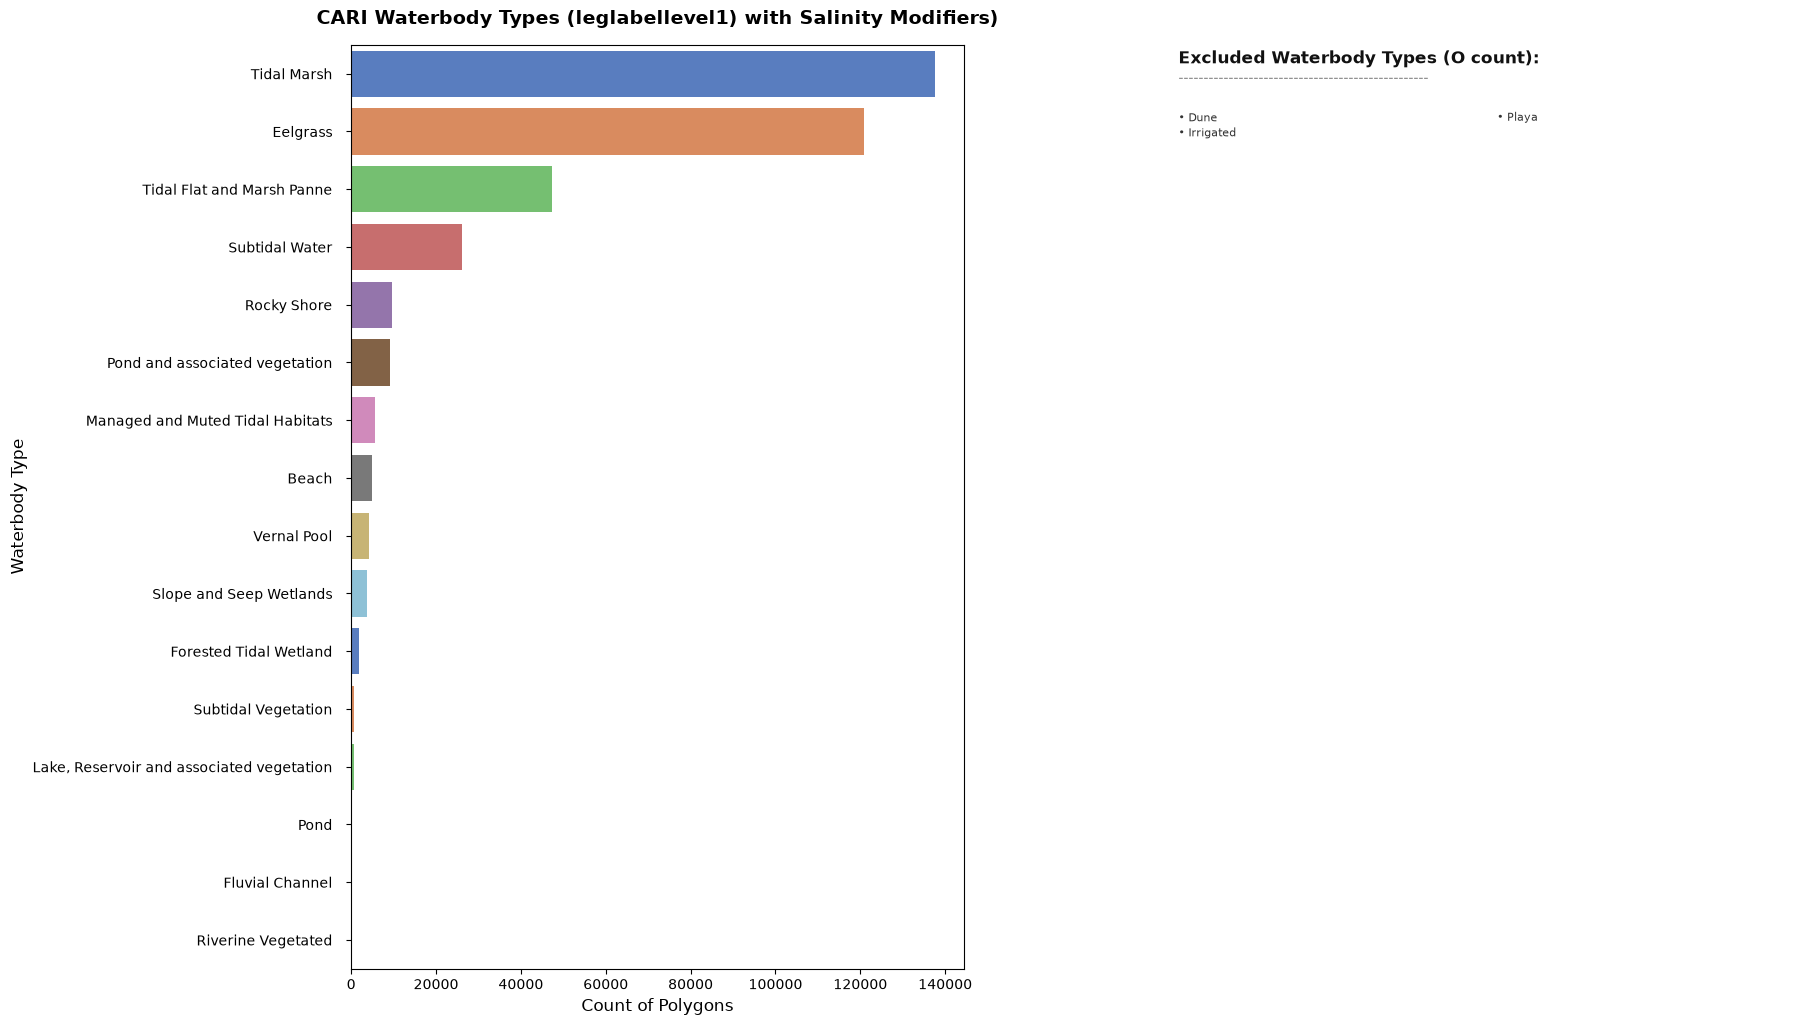

In [19]:
#Distribution of Waterbody types in CARI with Salinity Modifiers
# Distribution of CARI waterbody types with salinity modifiers, only major class

type_col = 'leglabellevel1' 

# --- Step 2: Separate and Filter Data (> 100 Counts) ---
plot_data = cari_sal[cari_sal[type_col].notna()]
active_counts = plot_data[type_col].value_counts()

# Only keep waterbody types with MORE THAN 100 entries
types_above_100 = active_counts[active_counts > 0].index
filtered_plot_data = plot_data[plot_data[type_col].isin(types_above_100)].copy()

# CRITICAL FIX: Tell pandas to drop the empty category tags completely
if hasattr(filtered_plot_data[type_col], 'cat'):
    filtered_plot_data[type_col] = filtered_plot_data[type_col].cat.remove_unused_categories()

# Everything else goes to the excluded list on the right
all_unique_types = set(gdf_cari[type_col].dropna().unique())
types_without_values = sorted(list(all_unique_types - set(types_above_100)))

# --- Step 3: Setup side-by-side layout ---
# Increased width to 18 and height to 12 to provide structural breathing room
fig, (ax_plot, ax_text) = plt.subplots(
    1, 2, figsize=(18, 12), gridspec_kw={'width_ratios': [2.5, 2.5]}  # Balanced 50/50 split
)

# --- Step 4: Plot the distribution (Seaborn) ---
sns.countplot(
    data=filtered_plot_data,
    y=type_col,
    order=types_above_100,  # Forces plot to sort highest to lowest
    ax=ax_plot,
    palette="muted"
)

# Change x-axis to log scale
#ax_plot.set_xscale('log')

ax_plot.set_title("CARI Waterbody Types (leglabellevel1) with Salinity Modifiers)", fontsize=14, pad=15, weight='bold')
ax_plot.set_xlabel("Count of Polygons", fontsize=12)
ax_plot.set_ylabel("Waterbody Type", fontsize=12)

# 🚀 Spacing optimization: adjust text padding on the y-axis
ax_plot.tick_params(axis='y', labelsize=10, pad=10) 

# --- Step 5: Split Excluded List into Two Balanced Columns ---
ax_text.axis('off') 

# Header text
ax_text.text(0.0, 0.98, "Excluded Waterbody Types (O count):", fontsize=12, weight='bold', color='#111111')
ax_text.text(0.0, 0.96, "-"*50, fontsize=10, color='#777777')

# Calculate the split point
half_size = int(np.ceil(len(types_without_values) / 2))
col1_items = types_without_values[:half_size]
col2_items = types_without_values[half_size:]

# Convert list slices to single text blocks
col1_text = "\n".join(f"• {item}" for item in col1_items)
col2_text = "\n".join(f"• {item}" for item in col2_items)

# Render Column 1 (Left side of the right panel)
ax_text.text(
    0.0, 0.93, col1_text, 
    transform=ax_text.transAxes, 
    fontsize=8, 
    verticalalignment='top',
    linespacing=1.4,
    color='#333333'
)

# Render Column 2 (Right side of the right panel)
ax_text.text(
    0.52, 0.93, col2_text, 
    transform=ax_text.transAxes, 
    fontsize=8, 
    verticalalignment='top',
    linespacing=1.4,
    color='#333333'
)

# Adjust layout bounding box properties to maximize canvas padding
plt.subplots_adjust(left=0.15, right=0.95, wspace=0.35)
plt.show()

C:\Users\SHordyk\AppData\Local\Temp\1\ipykernel_844\4104824726.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


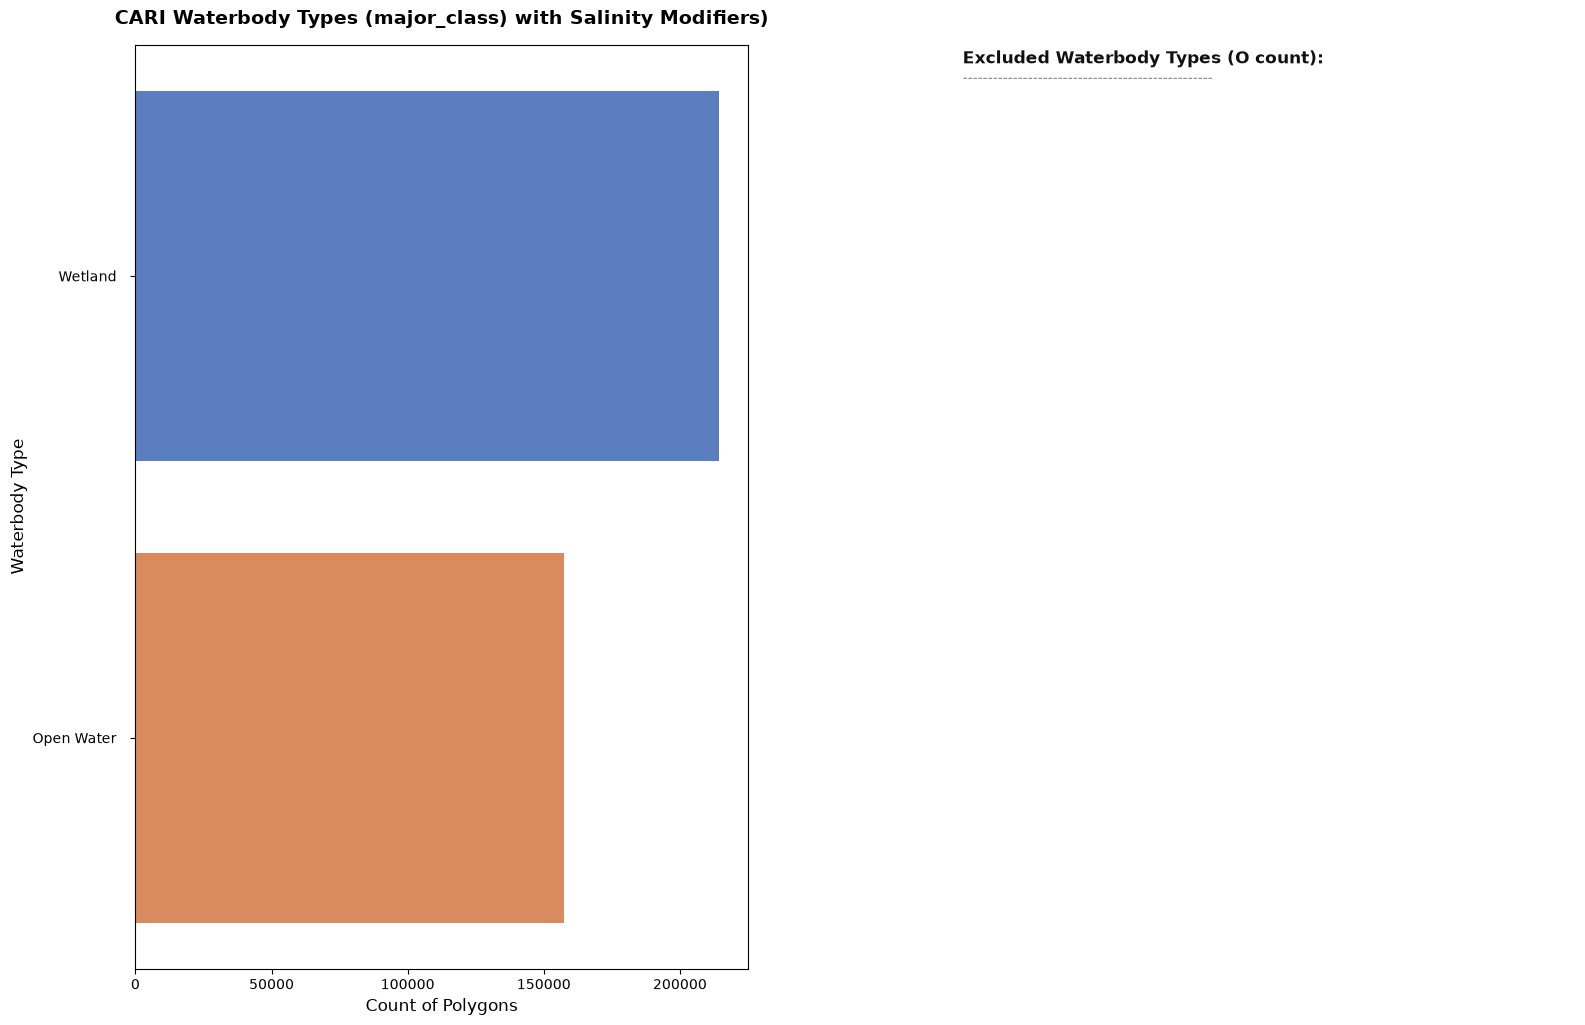

In [20]:
#Distribution of Waterbody types in CARI with Salinity Modifiers
# Distribution of CARI waterbody types with salinity modifiers, only major class

type_col = 'major_class' 

#Print count in cari_S

In [11]:
counts = (
    cari_sal[cari_sal["major_class"].isin(["Open Water", "Wetland"])]
    ["major_class"]
    .value_counts()
    .reindex(["Open Water", "Wetland"], fill_value=0)
)

open_water_count = counts["Open Water"]
wetland_count = counts["Wetland"]

print(f"Open Water: {open_water_count}")
print(f"Wetland: {wetland_count}")

Open Water: 157508
Wetland: 214364


In [12]:
df_ceden['ANALYTE'].value_counts()

ANALYTE
SpecificConductivity, Total           844418
Salinity, Total                       692156
SpecificConductivity, Not Recorded     58482
Chloride, Total                        19091
Chloride, Dissolved                    12181
Chloride, Not Recorded                  2146
Salinity, Dissolved                      669
SpecificConductivity                       3
Salinity                                   3
SpecificConductivity, Dissolved            2
Name: count, dtype: int64

['Salinity, Total', 'SpecificConductivity, Total', 'Chloride, Dissolved', 'Chloride, Total', 'SpecificConductivity, Not Recorded', 'Chloride, Not Recorded', 'SpecificConductivity, Dissolved', 'SpecificConductivity', 'Salinity', 'Salinity, Dissolved']


In [24]:
print(sorted(analytes))

['Acenaphthene, Total', 'Acenaphthylene, Total', 'Aldrin, Total', 'Alkalinity as CaCO3, Not Recorded', 'Alkalinity as CaCO3, Total', 'Aluminum, Dissolved', 'Aluminum, Total', 'Ammonia as N, Dissolved', 'Ammonia as N, Not Recorded', 'Ammonia as N, Total', 'Anthracene, Total', 'Antimony, Dissolved', 'Antimony, Total', 'Arsenic, Dissolved', 'Arsenic, Total', 'Azobenzene, Total', 'BOD, Not Recorded', 'BOD, Total', 'Barban(Surrogate), Dissolved', 'Barium, Total', 'Benz(a)anthracene, Total', 'Benzene, Total', 'Benzidine, Total', 'Benzo(a)pyrene, Total', 'Benzo(b)fluoranthene, Total', 'Benzo(e)pyrene, Total', 'Benzo(g,h,i)perylene, Total', 'Benzo(k)fluoranthene, Total', 'Beryllium, Dissolved', 'Beryllium, Total', 'Biphenyl, Total', 'Bis(2-chloroethoxy)methane, Total', 'Bis(2-chloroethyl)ether, Total', 'Bis(2-chloroisopropyl) ether, Total', 'Bis(2-ethylhexyl)phthalate, Total', 'Boron, Dissolved', 'Boron, Total', 'Bromide, Dissolved', 'Bromide, Total', 'Bromobenzene, Total', 'Bromochloromethane

In [ ]:
analytes = df_ceden['ANALYTE'].unique()
#searching for keywords related to salinity, conductivity, and conductance
salinity_related = [a for a in analytes if any(kw in a.lower() for kw in ['conductance', 'conductivity', 'salinity', 'chloride'])]
print(salinity_related)
salinity_analytes = ['Salinity, Total', 'Salinity', 'Salinity, Dissolved',
                      'SpecificConductivity, Total', 'SpecificConductivity',
                      'SpecificConductivity, Not Recorded', 'SpecificConductivity, Dissolved',
                      'Chloride, Total', 'Chloride, Dissolved', 'Chloride, Not Recorded']
# Creates a temporary true false mask for the analytes of interest, then groups by analyte and unit to get counts. Move to last line in cell to display
df_ceden[df_ceden['ANALYTE'].isin(salinity_analytes)].groupby(['ANALYTE', 'UNIT']).size()
df_ceden_salinity = df_ceden[df_ceden['ANALYTE'].isin(salinity_analytes)].copy()
df_ceden_salinity.shape

(1629151, 94)

In [ ]:
# Check values, look at units and such. Especially percent

In [ ]:
# Rough CEDEN -
# Filtering to just analytes first

In [ ]:
#Drop entries missing lat and long. EDUT want count of how many missing lat long
df_ceden_salinity = df_ceden_salinity.dropna(subset=['LATITUDE', 'LONGITUDE'])
# Extract unique STATIONCODE and STATIONNAME combinations to avoid duplicates in the GeoDataFrame
df_ceden_sal_u = df_ceden_salinity.drop_duplicates(subset=['STATIONCODE', 'STATIONNAME'])
# Drop entries with missing or NaN values in the 'RESULT' column
df_ceden_sal_u = df_ceden_sal_u.dropna(subset=['RESULT'])
df_ceden_sal_u.shape
#(12144, 94)


(12585, 94)

In [ ]:
#Checking what values exist for NWIS CharacteristicName, name of analyte. 
df_nwis['CharacteristicName'].value_counts()
# Looking at result values, whcih collumn do we want. ResultMeasureValue, ResultStatusIdentifier
df_nwis['ResultStatusIdentifier'].value_counts();
# Print values of ResultMeasureValue to see what they look like
df_nwis['ResultMeasure/MeasureUnitCode'].value_counts();
# Filtering NWIS as well. Dropping any without lat long, 
df_nwis = df_nwis.dropna(subset=['ActivityLocation/LatitudeMeasure', 'ActivityLocation/LongitudeMeasure'])
df_nwis.shape
# Dropping without any result values, ResultMeasureValue or unit. ResultMeasureValue is the actual measurement, ResultMeasure/MeasureUnitCode is the unit of measurement.
df_nwis = df_nwis.dropna(subset=['ResultMeasureValue', 'ResultMeasure/MeasureUnitCode'])
df_nwis.shape
# Keeping only columns needed. MonitoringLocationIdentifier, MonitoringLocationName, ActivityLocation/LatitudeMeasure, ActivityLocation/LongitudeMeasure, ActivityStartDate, CharacteristicName, ResultMeasureValue, ResultMeasure/MeasureUnitCode, ResultSampleFractionText, ResultDetectionConditionText, ResultStatusIdentifier, MeasureQualifierCode, OrganizationIdentifier, OrganizationFormalName, USGSPCode
df_nwis_sal = df_nwis[['MonitoringLocationIdentifier', 'MonitoringLocationName', 'ActivityLocation/LatitudeMeasure', 'ActivityLocation/LongitudeMeasure', 'ActivityStartDate', 'CharacteristicName', 'ResultMeasureValue', 'ResultMeasure/MeasureUnitCode', 'ResultSampleFractionText', 'ResultDetectionConditionText', 'ResultStatusIdentifier', 'MeasureQualifierCode', 'OrganizationIdentifier', 'OrganizationFormalName', 'USGSPCode']]
#Keep only columns needed: STATIONCODE, STATIONNAME, LATITUDE, LONGITUDE, ANALYTE, UNIT, RESULT, RESULTQUALCODE, MDL, RL
df_ceden_sal_u = df_ceden_sal_u[['STATIONCODE', 'STATIONNAME', 'LATITUDE', 'LONGITUDE', 'ANALYTE', 'UNIT', 'RESULT', 'RESULTQUALCODE', 'MDL', 'RL']]
df_ceden_sal_u.head()
df_ceden_sal_u.shape


In [18]:
# Filtering NWIS as well. Dropping any without lat long, 
df_nwis = df_nwis.dropna(subset=['ActivityLocation/LatitudeMeasure', 'ActivityLocation/LongitudeMeasure'])
df_nwis.shape
# Dropping without any result values, ResultMeasureValue or unit. ResultMeasureValue is the actual measurement, ResultMeasure/MeasureUnitCode is the unit of measurement.
df_nwis = df_nwis.dropna(subset=['ResultMeasureValue', 'ResultMeasure/MeasureUnitCode'])
df_nwis.shape
# Keeping only columns needed. MonitoringLocationIdentifier, MonitoringLocationName, ActivityLocation/LatitudeMeasure, ActivityLocation/LongitudeMeasure, ActivityStartDate, CharacteristicName, ResultMeasureValue, ResultMeasure/MeasureUnitCode, ResultSampleFractionText, ResultDetectionConditionText, ResultStatusIdentifier, MeasureQualifierCode, OrganizationIdentifier, OrganizationFormalName, USGSPCode
df_nwis_sal = df_nwis[['MonitoringLocationIdentifier', 'MonitoringLocationName', 'ActivityLocation/LatitudeMeasure', 'ActivityLocation/LongitudeMeasure', 'ActivityStartDate', 'CharacteristicName', 'ResultMeasureValue', 'ResultMeasure/MeasureUnitCode', 'ResultSampleFractionText', 'ResultDetectionConditionText', 'ResultStatusIdentifier', 'MeasureQualifierCode', 'OrganizationIdentifier', 'OrganizationFormalName', 'USGSPCode']]

In [19]:
#Keep only columns needed: STATIONCODE, STATIONNAME, LATITUDE, LONGITUDE, ANALYTE, UNIT, RESULT, RESULTQUALCODE, MDL, RL
df_ceden_sal_u = df_ceden_sal_u[['STATIONCODE', 'STATIONNAME', 'LATITUDE', 'LONGITUDE', 'ANALYTE', 'UNIT', 'RESULT', 'RESULTQUALCODE', 'MDL', 'RL']]
df_ceden_sal_u.head()
df_ceden_sal_u.shape

(12116, 10)

In [20]:
#Build a GeoDataFrame from the station table
gpd_ceden_sal = gpd.GeoDataFrame(df_ceden_sal_u, geometry=gpd.points_from_xy(df_ceden_sal_u['LONGITUDE'], df_ceden_sal_u['LATITUDE']), crs="EPSG:4326")
#Check CARI crs
gpd_ceden_sal.crs
#Confrmed 4326, now reproject to match CARI
gpd_ceden_sal = gpd_ceden_sal.to_crs(gdf_cari.crs)

In [21]:
#Spatial join to find how many CARI polygons have matching CEDEN stations. This will help us understand how many waterbodies have salinity data available.
gpd_ceden_cari_joined = gpd.sjoin(gpd_ceden_sal, gdf_cari, how="left", predicate='intersects')


In [22]:
matched_stations = gpd_ceden_cari_joined[gpd_ceden_cari_joined['CARI_id'].notna()]['STATIONCODE'].nunique()
total_stations = gpd_ceden_sal['STATIONCODE'].nunique()
print(f"Stations matched to a CARI polygon: {matched_stations} / {total_stations}")

Stations matched to a CARI polygon: 3227 / 12111


In [24]:
# Count the number of unique CARI polygons that have matching CEDEN stations
unique_cari_with_stations = gpd_ceden_cari_joined['CARI_id'].nunique()
print(f"Number of unique CARI polygons with matching CEDEN stations: {unique_cari_with_stations}")
#pRInt the total number of unique CARI polygons
total_unique_cari = gdf_cari['CARI_id'].nunique()
print(f"Total number of unique CARI polygons: {total_unique_cari}")

Number of unique CARI polygons with matching CEDEN stations: 1863
Total number of unique CARI polygons: 1287921


In [25]:
#Testing, print salinity value for a CARI polygon using entry from gpd_ceden_cari_joined. This will help us understand how many waterbodies have salinity data available.
gpd_ceden_cari_joined[['CARI_id', 'STATIONCODE', 'RESULT']].head(10) 
# Want to clear out entries that have NaN or missing values in result column
gpd_ceden_cari_joined = gpd_ceden_cari_joined.dropna(subset=['RESULT'])
unique_cari_with_stations = gpd_ceden_cari_joined['CARI_id'].nunique()
print(f"Number of unique CARI polygons with matching CEDEN stations and no NaN result values: {unique_cari_with_stations}")


Number of unique CARI polygons with matching CEDEN stations and no NaN result values: 1863


In [26]:
#Repeating the process for NWIS data. Build a GeoDataFrame from the NWIS data, then perform a spatial join with CARI polygons to see how many waterbodies have salinity data available.
gpd_nwis_sal = gpd.GeoDataFrame(df_nwis_sal, geometry=gpd.points_from_xy(df_nwis_sal['ActivityLocation/LongitudeMeasure'], df_nwis_sal['ActivityLocation/LatitudeMeasure']), crs="EPSG:4326")   
gpd_nwis_sal.crs #Looks good, now reproject to match CARI
gpd_nwis_sal = gpd_nwis_sal.to_crs(gdf_cari.crs)

In [28]:
df_nwis_sal['MonitoringLocationIdentifier'].value_counts()

MonitoringLocationIdentifier
21CAOCSD_WQX-2103    219126
KARUKDNR_WQX-SA       29044
KARUKDNR_WQX-OR       26701
KARUKDNR_WQX-SV       26561
KARUKDNR_WQX-IG       25833
                      ...  
CEDEN-723STUD05           1
CEDEN-514SSC190           1
AREMP-CASQW0003           1
CEDEN-203R04055           1
CEDEN-204R04816           1
Name: count, Length: 9942, dtype: int64

NWIS Stations matched to a CARI polygon: 3233 / 9942


In [27]:
#Spatial join to find how many CARI polygons have matching NWIS stations. This will help us understand how many waterbodies have salinity data available.
gpd_nwis_cari_joined = gpd.sjoin(gpd_nwis_sal, gdf_cari, how="left", predicate='intersects')
matched_stations = gpd_nwis_cari_joined[gpd_nwis_cari_joined['CARI_id'].notna()]['MonitoringLocationIdentifier'].nunique()
total_stations = gpd_nwis_sal['MonitoringLocationIdentifier'].nunique()
print(f"NWIS Stations matched to a CARI polygon: {matched_stations} / {total_stations}")


NWIS Stations matched to a CARI polygon: 3233 / 9942


In [28]:

df_s2s = pd.read_csv(r"C:\Users\SHordyk\Desktop\safetoswim-waterbodies\data\raw\S2S_stations_2026-09-18-1455.csv")
# Spatial join to check how many CARI stations with salinity (cari_sal) overlap with Safe to Swim monitoring locations
#First turn s2s into gdf
gdf_s2s = gpd.GeoDataFrame(df_s2s, geometry=gpd.points_from_xy(df_s2s['TARGETLONGITUDE'], df_s2s['TARGETLONGITUDE']), crs="EPSG:4326")   
s2s_cari_sal = gpd.sjoin(gdf_s2s, cari_sal, how="left", predicate='intersects')




C:\Users\SHordyk\AppData\Local\Temp\1\ipykernel_25936\2803608130.py:5: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: EPSG:4326
Right CRS: EPSG:6414

  s2s_cari_sal = gpd.sjoin(gdf_s2s, cari_sal, how="left", predicate='intersects')


In [29]:
# Rebuild S2S points with the correct latitude and longitude columns
gdf_s2s = gpd.GeoDataFrame(
    df_s2s,
    geometry=gpd.points_from_xy(
        df_s2s["TARGETLONGITUDE"],
        df_s2s["TARGETLATITUDE"]
    ),
    crs="EPSG:4326"
).to_crs(cari_sal.crs)

# Spatially join S2S monitoring locations to CARI polygons with salinity modifiers
s2s_cari_sal = gpd.sjoin(
    gdf_s2s,
    cari_sal[["CARI_id", "geometry"]],
    how="left",
    predicate="intersects"
)

matched_s2s = s2s_cari_sal.loc[
    s2s_cari_sal["CARI_id"].notna(),
    "STATIONCODE"
].nunique()

total_s2s = gdf_s2s["STATIONCODE"].nunique()

print(f"S2S monitoring locations matched to CARI salinity polygons: {matched_s2s} / {total_s2s}")

S2S monitoring locations matched to CARI salinity polygons: 1253 / 6648


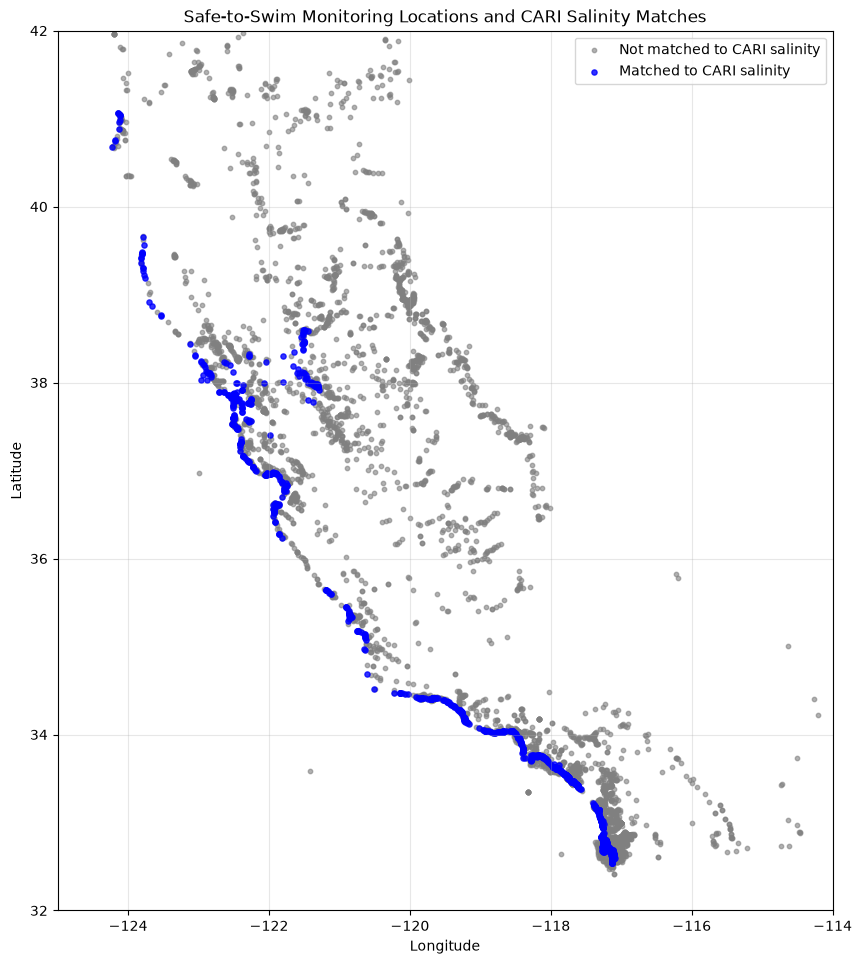

In [30]:
# Quick map of Safe-to-Swim monitoring locations matched to CARI salinity polygons

# Identify stations matched to a CARI salinity polygon
matched_station_codes = set(
    s2s_cari_sal.loc[
        s2s_cari_sal["CARI_id"].notna(),
        "STATIONCODE"
    ]
)

# Reproject points to longitude/latitude for plotting
s2s_map = gdf_s2s.to_crs("EPSG:4326").copy()
s2s_map["matched_cari_salinity"] = s2s_map["STATIONCODE"].isin(
    matched_station_codes
)

fig, ax = plt.subplots(figsize=(10, 12))

# Plot unmatched locations first
s2s_map[~s2s_map["matched_cari_salinity"]].plot(
    ax=ax,
    color="gray",
    markersize=10,
    alpha=0.6,
    label="Not matched to CARI salinity"
)

# Plot matched locations
s2s_map[s2s_map["matched_cari_salinity"]].plot(
    ax=ax,
    color="blue",
    markersize=14,
    alpha=0.8,
    label="Matched to CARI salinity"
)

ax.set_xlim(-125, -114)
ax.set_ylim(32, 42)
ax.set_title("Safe-to-Swim Monitoring Locations and CARI Salinity Matches")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()
ax.grid(True, alpha=0.3)

plt.show()

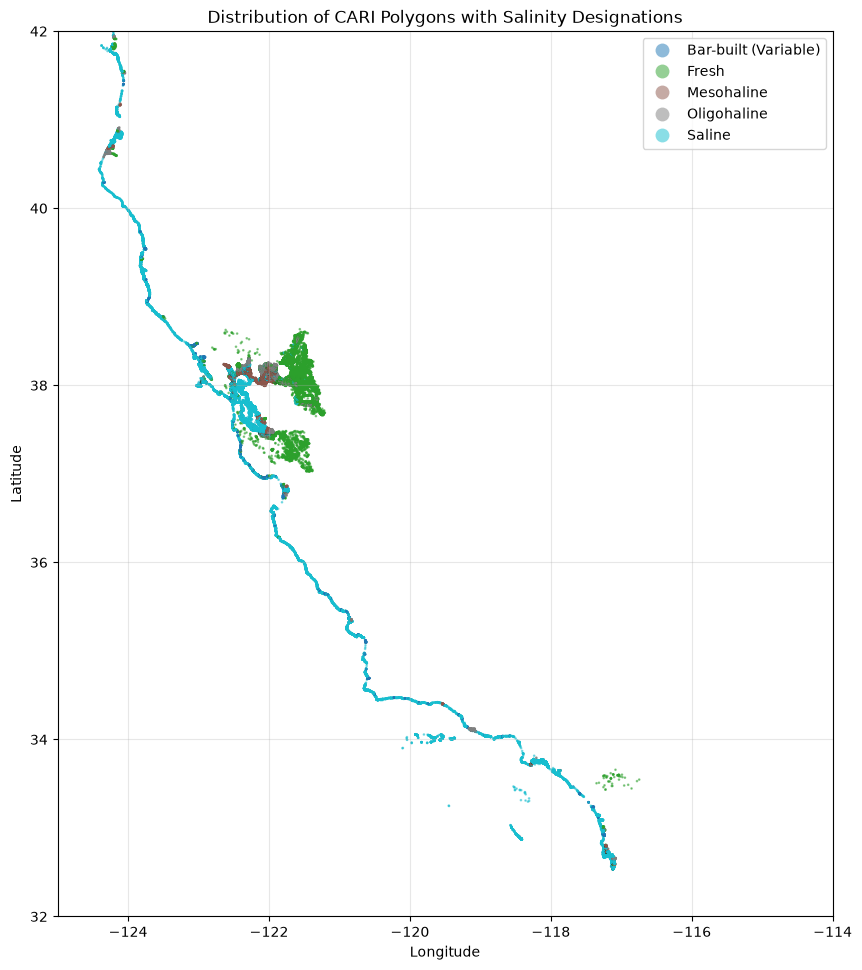

In [31]:
# Quick point map of CARI polygons with salinity designations

cari_sal_points = cari_sal.copy()
cari_sal_points["geometry"] = cari_sal_points.geometry.representative_point()
cari_sal_points = cari_sal_points.to_crs("EPSG:4326")

fig, ax = plt.subplots(figsize=(10, 12))

cari_sal_points.plot(
    ax=ax,
    column="salinity_modifier",
    categorical=True,
    legend=True,
    markersize=0.8,
    alpha=0.5
)

ax.set_title("Distribution of CARI Polygons with Salinity Designations")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_xlim(-125, -114)
ax.set_ylim(32, 42)
ax.grid(True, alpha=0.3)

plt.show()

In [ ]:
# Doing spatial join with both datasets to see how many waterbodies have either CEDEN or NWIS salinity data available.
# List of matched CARI ids for gpd_ceden_cari_joined and gpd_nwis_cari_joined
matched_cari_ids = set(gpd_ceden_cari_joined['CARI_id'].dropna()) | set(gpd_nwis_cari_joined['CARI_id'].dropna())
print(len(matched_cari_ids))



2793


In [46]:
total_cari = gdf_cari['CARI_id'].nunique()
print(f"CARI polygons with CEDEN or NWIS data: {len(matched_cari_ids)} / {total_cari}")

CARI polygons with CEDEN or NWIS data: 2793 / 1287921
